In [ ]:

%pip install "rembg[cpu]" pillow


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving Image.jpeg to Image.jpeg


  0%|                                              | 0.00/1.02G [00:00<?, ?B/s]

Background removed successfully!


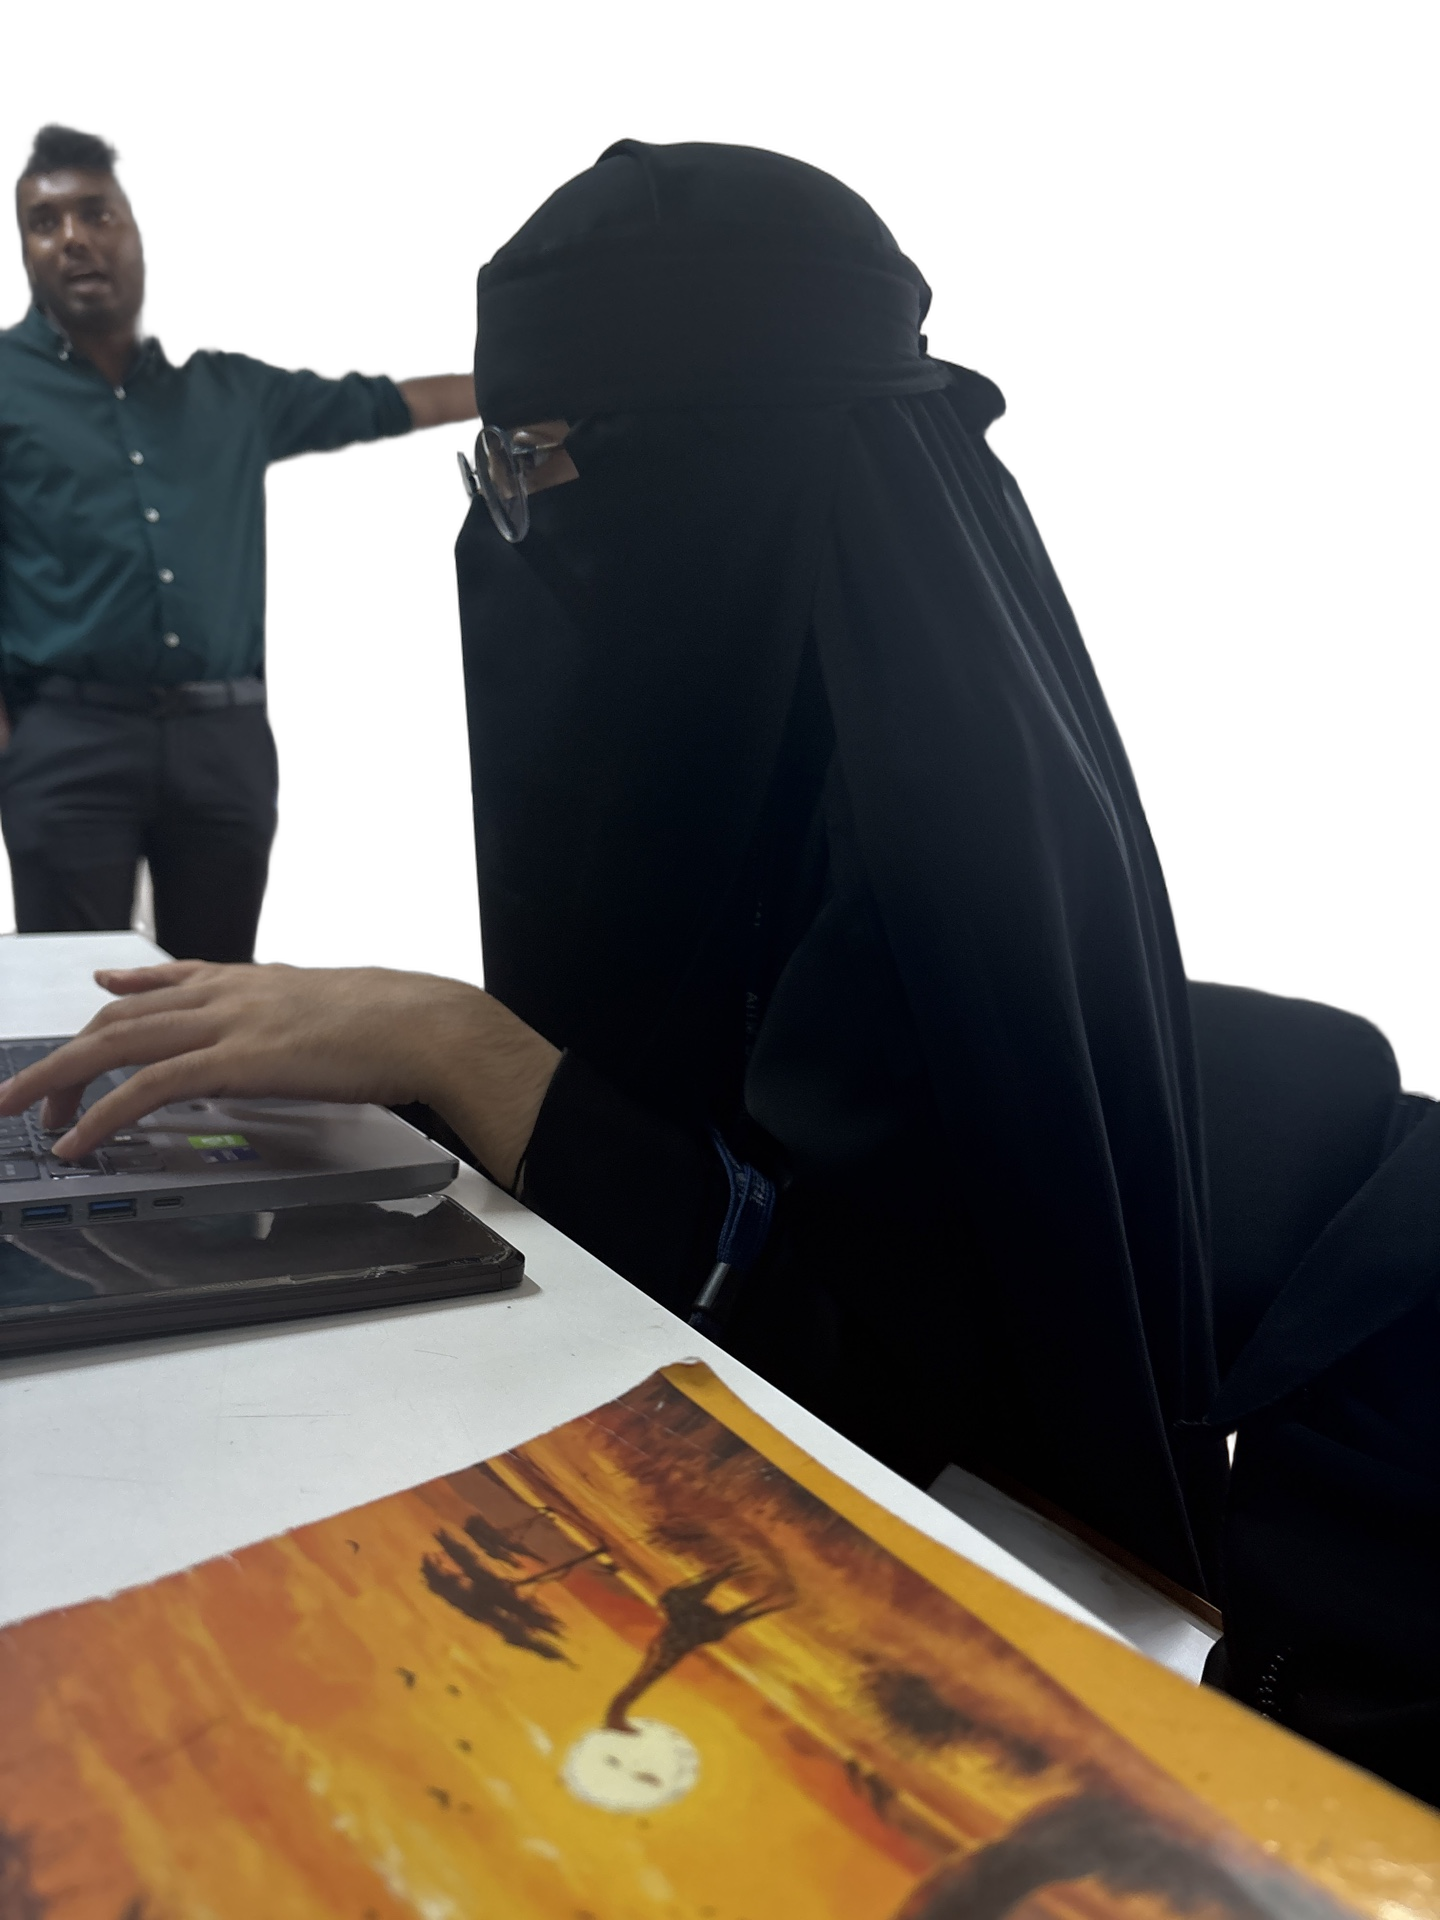

In [ ]:

from rembg import remove
from PIL import Image
from IPython.display import display

input_path = list(uploaded.keys())[0]
output_path = "output.png"

input_image = Image.open(input_path)
output_image = remove(input_image)
output_image.save(output_path)

print("Background removed successfully!")
display(output_image)


In [ ]:
%pip install "gTTS==2.5.4" "click==8.1.8"

In [ ]:
from gtts import gTTS
from IPython.display import Audio, display
import os

text = "Hello All, This is the introduction of text to speech conversion using Python."

tts = gTTS(text=text, lang="en", slow=False)
tts.save("speech.mp3")

print("Speech generated successfully!")
print("File exists:", os.path.exists("speech.mp3"))

display(Audio(filename="speech.mp3"))

Speech generated successfully!
File exists: True


In [ ]:
!pip install streamlit gTTS

In [ ]:

%%writefile app.py
import streamlit as st
from gtts import gTTS
from io import BytesIO

st.set_page_config(
    page_title="Text to Speech",
    page_icon="🔊"
)

st.title("🔊 Text to Speech")

text = st.text_area("Enter your text:", height=150)

if st.button("Convert to Speech"):
    if text.strip():
        audio = BytesIO()
        tts = gTTS(text=text, lang="en")
        tts.write_to_fp(audio)
        audio.seek(0)

        st.audio(audio, format="audio/mp3")

        st.download_button(
            "Download Audio",
            data=audio.getvalue(),
            file_name="speech.mp3",
            mime="audio/mpeg"
        )
    else:
        st.warning("Please enter some text.")


Writing app.py


In [ ]:

languages = {
    "English": "en",
    "Hindi": "hi",
    "Kannada": "kn",
    "Marathi": "mr",
    "Tamil": "ta",
    "Telugu": "te",
}

# Dropdown to select language
lang_name = st.selectbox(
    "Language:",
    list(languages.keys())
)

# Checkbox for speech speed
slow = st.checkbox("Speak slowly")

# Debug line (disabled)
# print(f"Selected language: {lang_name}, Slow: {slow}")


2026-10-15 10:50:11.522 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 10:50:11.524 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 10:50:11.526 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 10:50:11.527 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 10:50:11.528 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 10:50:11.529 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 10:50:11.530 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 10:50:11.532 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [ ]:
!tail -30 /content/streamlit.log



2026-10-15 10:47:59.915 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.13.174.27:8501



In [ ]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Thu, 15 Oct 2026 10:50:17 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Thu, 15 Oct 2026 10:42:23 GMT
etag: "9af87e9ae1c4a7935cccf4b9576a8522"
cache-control: no-cache



In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
!streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false --server.enableWebsocketCompression false &>/content/streamlit.log &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>